In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Set project folders
PROJECT_DIR = Path(r"C:\Users\Preetham\Downloads\collections_30k_dataset (1)")
REPORTS_DIR = PROJECT_DIR / "reports"
QUALITY_DIR = PROJECT_DIR / "quality_reports"

print("Project folder:", PROJECT_DIR)
print("Reports folder exists:", REPORTS_DIR.exists())
print("Quality reports folder exists:", QUALITY_DIR.exists())

Project folder: C:\Users\Preetham\Downloads\collections_30k_dataset (1)
Reports folder exists: True
Quality reports folder exists: True


In [2]:
# Load the Golden Dataset
golden_file = REPORTS_DIR / "golden_payments_dataset.csv"

golden = pd.read_csv(golden_file)

print("Golden Dataset loaded successfully!")
print("Number of rows:", len(golden))
print("Number of columns:", len(golden.columns))

display(golden.head())

Golden Dataset loaded successfully!
Number of rows: 25014
Number of columns: 20


,payment_id,account_id,borrower_id_x,event_at,payment_reference,amount,payment_status,payment_method,provider_id,payment_id_duplicate,borrower_id_y,loan_type,risk_segment,dpd,principal_amount,timezone,opened_at,account_match_status,missing_payment_reference,invalid_amount
0,PAYMENT0000001,ACC0015539,BRW0011363,2026-02-27 01:28:12+00:00,TXN0000007457,22433.23,FAILED,CARD,VND0000001,False,BRW0010501,BNPL,LOW,30,728134.07,UTC,2024-09-04 15:24:13,MATCHED,False,False
1,PAYMENT0000002,ACC0004445,BRW0011306,2026-07-23 20:25:20+00:00,TXN0000030016,23295.11,FAILED,UPI,VND0000004,False,BRW0003278,BNPL,NPA,45,358982.23,Asia/Kolkata,2024-09-04 07:25:53,MATCHED,False,False
2,PAYMENT0000003,ACC0003853,BRW0002549,2026-01-11 21:27:46+00:00,TXN0000010466,118814.97,FAILED,NACH,VND0000013,False,BRW0007156,BNPL,HIGH,30,66139.49,Asia/Kolkata,2024-04-23 23:22:52,MATCHED,False,False
3,PAYMENT0000004,ACC0017531,BRW0006618,2026-06-16 02:35:21+00:00,TXN0000031781,145082.17,REVERSED,CASH,VND0000013,False,BRW0001549,PERSONAL,LOW,60,683048.93,Asia/Kolkata,2025-01-19 23:49:29,MATCHED,False,False
4,PAYMENT0000005,ACC0001770,BRW0011492,2026-03-03 06:08:23+00:00,TXN0000059257,115148.46,SUCCESS,NETBANKING,VND0000013,False,BRW0008515,AUTO,HIGH,90,13351.36,Asia/Dubai,2025-07-19 13:48:05,MATCHED,False,False


In [3]:

# Check missing values, duplicates, statuses, and amounts

print("=== DATASET OVERVIEW ===")
print("Rows:", len(golden))
print("Columns:", len(golden.columns))

print("\n=== MISSING VALUES ===")
display(
    golden.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

print("\n=== PAYMENT STATUS COUNTS ===")
display(golden["payment_status"].value_counts(dropna=False).to_frame("count"))

print("\n=== DUPLICATE PAYMENT IDs ===")
print("Rows flagged as duplicate:", golden["payment_id_duplicate"].sum())
print("Repeated payment IDs:", golden.loc[
    golden["payment_id_duplicate"], "payment_id"
].nunique())

print("\n=== PAYMENT AMOUNT CHECK ===")
print("Minimum amount:", golden["amount"].min())
print("Maximum amount:", golden["amount"].max())
print("Zero or negative amounts:", (golden["amount"] <= 0).sum())

print("\n=== BORROWER ID COMPARISON ===")
print(
    "Rows where borrower IDs differ:",
    (golden["borrower_id_x"] != golden["borrower_id_y"]).sum()
)


=== DATASET OVERVIEW ===
Rows: 25014
Columns: 20

=== MISSING VALUES ===


,missing_count
borrower_id_y,383
payment_reference,382
payment_id,0
account_id,0
event_at,0
borrower_id_x,0
payment_status,0
amount,0
payment_method,0
provider_id,0



=== PAYMENT STATUS COUNTS ===


,count
payment_status,
SUCCESS,17545
FAILED,3678
PENDING,2536
REVERSED,1255



=== DUPLICATE PAYMENT IDs ===
Rows flagged as duplicate: 28
Repeated payment IDs: 14

=== PAYMENT AMOUNT CHECK ===
Minimum amount: 103.68
Maximum amount: 149993.55
Zero or negative amounts: 0

=== BORROWER ID COMPARISON ===
Rows where borrower IDs differ: 25013


In [4]:

# Convert payment timestamps and calculate monthly successful payments

golden["event_at"] = pd.to_datetime(golden["event_at"], utc=True)
golden["month"] = golden["event_at"].dt.to_period("M").astype(str)

successful = golden[golden["payment_status"] == "SUCCESS"].copy()

monthly = (
    successful.groupby("month")
    .agg(
        successful_payment_rows=("payment_id", "size"),
        unique_payment_ids=("payment_id", "nunique"),
        unique_accounts=("account_id", "nunique"),
        gross_success_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("month")
)

monthly["amount_change_pct"] = (
    monthly["gross_success_amount"].pct_change() * 100
).round(2)

monthly["payment_id_change_pct"] = (
    monthly["unique_payment_ids"].pct_change() * 100
).round(2)

monthly["account_change_pct"] = (
    monthly["unique_accounts"].pct_change() * 100
).round(2)

display(monthly.round(2))


C:\Users\Preetham\AppData\Local\Temp\ipykernel_15772\4115855681.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  golden["month"] = golden["event_at"].dt.to_period("M").astype(str)


,month,successful_payment_rows,unique_payment_ids,unique_accounts,gross_success_amount,amount_change_pct,payment_id_change_pct,account_change_pct
0,2026-01,2464,2464,2374,1.872291e+08,NaN,NaN,NaN
1,2026-02,2270,2268,2173,1.702796e+08,-9.05,-7.95,-8.47
2,2026-03,2527,2524,2419,1.891903e+08,11.11,11.29,11.32
3,2026-04,2407,2406,2304,1.752289e+08,-7.38,-4.68,-4.75
4,2026-05,2450,2449,2344,1.843355e+08,5.20,1.79,1.74
5,2026-06,2369,2366,2286,1.758534e+08,-4.60,-3.39,-2.47
6,2026-07,2442,2441,2335,1.872478e+08,6.48,3.17,2.14
7,2026-08,616,616,608,4.710970e+07,-74.84,-74.76,-73.96


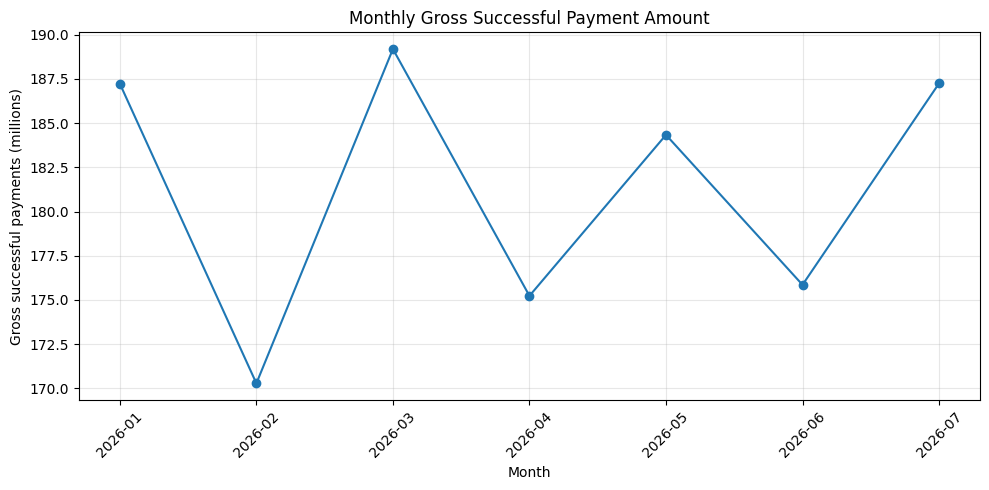

Chart saved to: C:\Users\Preetham\Downloads\collections_30k_dataset (1)\reports\notebook_monthly_recovery_trend.png


In [5]:

# Plot and save monthly gross successful payment amounts

plot_data = monthly[monthly["month"] != "2026-08"].copy()

plt.figure(figsize=(10, 5))
plt.plot(
    plot_data["month"],
    plot_data["gross_success_amount"] / 1_000_000,
    marker="o"
)

plt.title("Monthly Gross Successful Payment Amount")
plt.xlabel("Month")
plt.ylabel("Gross successful payments (millions)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

chart_path = REPORTS_DIR / "notebook_monthly_recovery_trend.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


In [6]:

# Summarize the key findings from the analysis

positive_months = int((monthly["amount_change_pct"] > 0).sum())
full_months = monthly[monthly["month"] != "2026-08"]

print("RECOVERY ANALYSIS — KEY FINDINGS")
print("-" * 40)
print(f"Golden Dataset rows: {len(golden):,}")
print(f"Successful payment rows: {(golden['payment_status'] == 'SUCCESS').sum():,}")
print(f"Missing payment references: {golden['missing_payment_reference'].sum():,}")
print(f"Rows flagged as duplicate payment IDs: {golden['payment_id_duplicate'].sum():,}")
print(f"Full-month comparisons with an increase: {positive_months}")
print()

march_change = monthly.loc[
    monthly["month"] == "2026-03", "amount_change_pct"
].iloc[0]

print(f"March gross successful payment change: {march_change:.2f}%")
print(
    "Conclusion: The data shows a one-month increase of about 11% in March, "
    "but not a sustained 11% month-on-month improvement."
)
print(
    "Limitation: Gross successful payment amount is not a recovery rate. "
    "A suitable eligible-balance denominator and reversal treatment are needed."
)
print(
    "Data-quality limitation: Borrower attribution differs across joined "
    "borrower ID columns and requires investigation."
)


RECOVERY ANALYSIS — KEY FINDINGS
----------------------------------------
Golden Dataset rows: 25,014
Successful payment rows: 17,545
Missing payment references: 382
Rows flagged as duplicate payment IDs: 28
Full-month comparisons with an increase: 3

March gross successful payment change: 11.11%
Conclusion: The data shows a one-month increase of about 11% in March, but not a sustained 11% month-on-month improvement.
Limitation: Gross successful payment amount is not a recovery rate. A suitable eligible-balance denominator and reversal treatment are needed.
Data-quality limitation: Borrower attribution differs across joined borrower ID columns and requires investigation.
